# Breast Ultrasound Classification — EfficientNetB0 + Random Forest / XGBoost

In [1]:

import os
import random
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image

from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# Dataset paths
base_dir = ("C:\\Django\\BreastCancer\\ultrasound breast classification")

train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")

In [3]:
# Dataset configuration
IMG_SIZE = (128, 128)
BATCH_SIZE = 64

# Load training dataset
train_gen = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Load validation dataset
val_gen = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Normalization and performance optimization
def preprocess(image, label):
    """Convert image to float32 and normalize pixel values."""
    image = tf.image.convert_image_dtype(image, tf.float32)
    return image, label


train_gen = (
    train_gen.map(preprocess)
    .cache()
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

val_gen = (
    val_gen.map(preprocess)
    .cache()
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)


Found 8116 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


# Section A) Deep learning

# Model 1 - VGG16

In [5]:
# Model construction
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze convolutional base layers
for layer in base_model.layers:
    layer.trainable = False

# Define the classification model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
# Model training configuration
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "vgg16_best.keras",
        save_best_only=True
    )
]

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=callbacks
)


Epoch 1/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 212s 2s/step - accuracy: 0.6344 - loss: 1.4053 - val_accuracy: 0.7844 - val_loss: 0.5381
Epoch 2/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 205s 2s/step - accuracy: 0.7180 - loss: 0.8356 - val_accuracy: 0.8067 - val_loss: 0.4754
Epoch 3/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 200s 2s/step - accuracy: 0.7623 - loss: 0.6173 - val_accuracy: 0.8267 - val_loss: 0.3945
Epoch 4/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.7985 - loss: 0.4878 - val_accuracy: 0.8467 - val_loss: 0.3594
Epoch 5/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.8122 - loss: 0.4272 - val_accuracy: 0.8489 - val_loss: 0.3510
Epoch 6/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 199s 2s/step - accuracy: 0.8291 - loss: 0.3843 - val_accuracy: 0.8433 - val_loss: 0.3434
Epoch 7/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step - accuracy: 0.8551 - loss: 0.3402 - val_accuracy: 0.8556 - val_loss: 0.3094
Epoch 8/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - accuracy: 0.8645 - loss: 0.3119 - val_accu

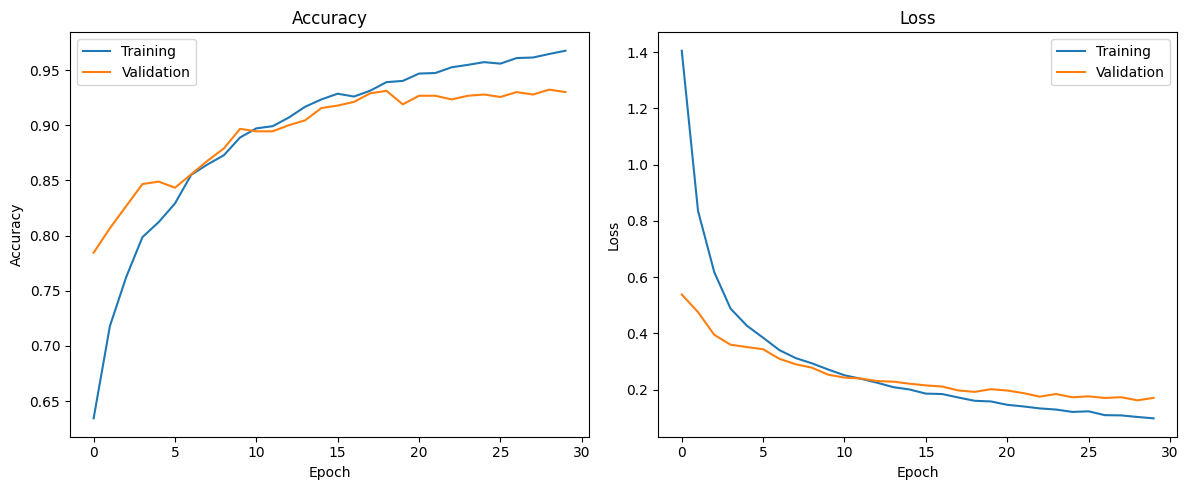

In [8]:
# Learning curves
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [10]:
model.save("vgg16_breast_cancer_ultrasound.h5")

In [9]:
# Final evaluation
loss, acc = model.evaluate(val_gen)
print(f"\nValidation accuracy: {acc * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9322 - loss: 0.1616

Validation accuracy: 93.22%


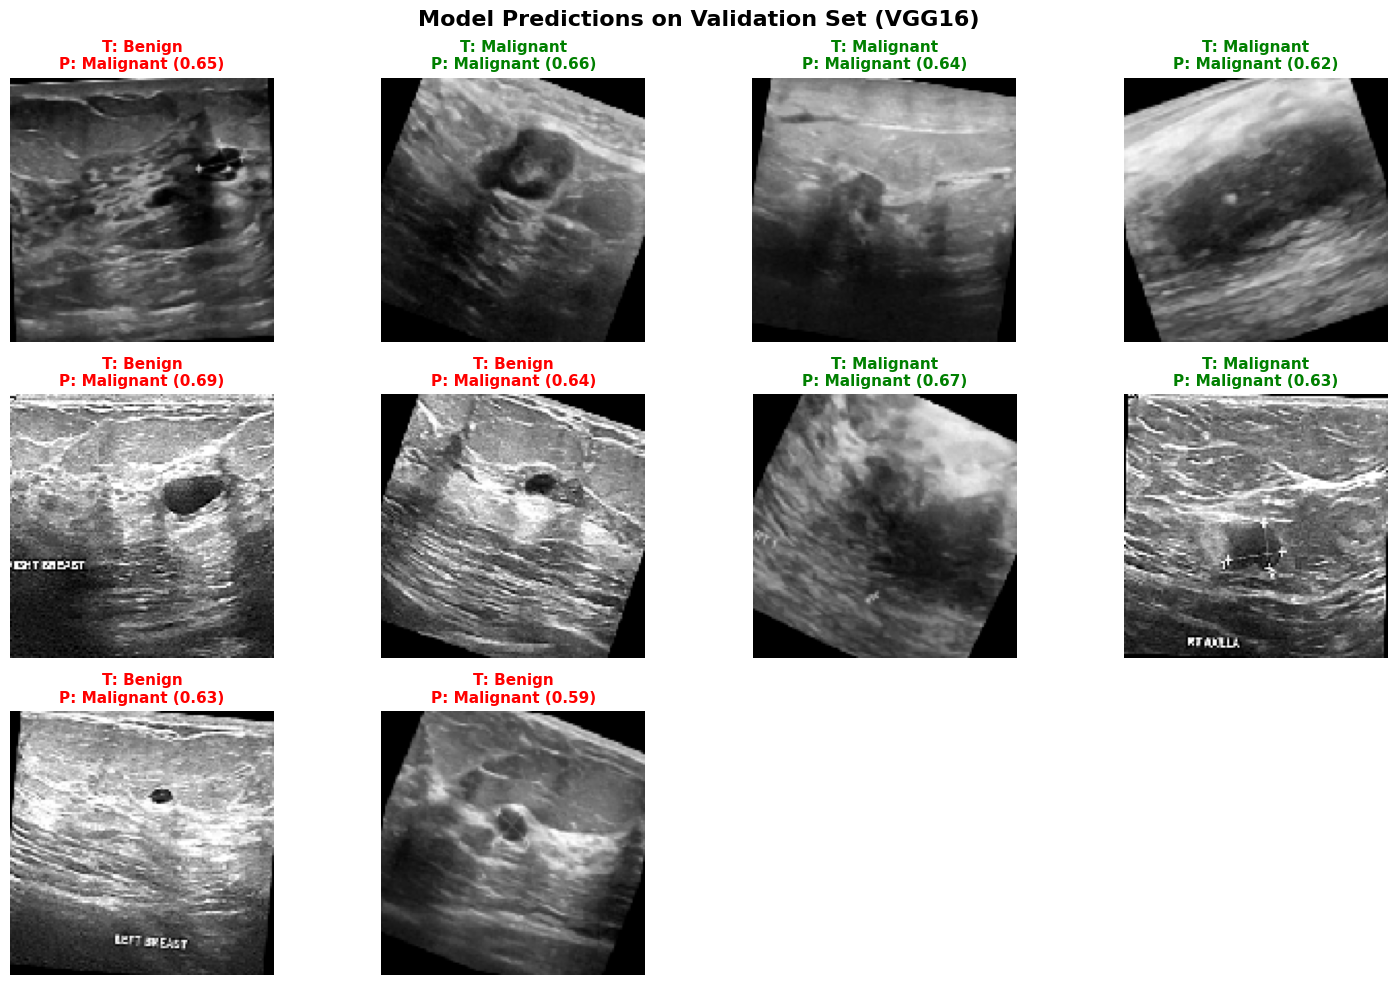

In [8]:
# Model loading and configuration
model = load_model("/kaggle/working/vgg16_best.keras")

# Validation dataset directories
val_base = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val"
)
benign_dir = os.path.join(val_base, "benign")
malignant_dir = os.path.join(val_base, "malignant")

# Collect all image paths
benign_imgs = [
    os.path.join(benign_dir, f)
    for f in os.listdir(benign_dir)
    if f.endswith((".png", ".jpg", ".jpeg"))
]
malignant_imgs = [
    os.path.join(malignant_dir, f)
    for f in os.listdir(malignant_dir)
    if f.endswith((".png", ".jpg", ".jpeg"))
]

# Select random samples from each class
sample_imgs = random.sample(benign_imgs, 5) + random.sample(malignant_imgs, 5)
random.shuffle(sample_imgs)


# Prediction function
def predict_image(img_path):
    """Predicts the class and probability for a single image."""
    img = image.load_img(img_path, target_size=(128, 128))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prob = model.predict(img_array, verbose=0)[0][0]
    pred_class = "Malignant" if prob > 0.5 else "Benign"
    return pred_class, prob, img


# Visualization of predictions
plt.figure(figsize=(15, 10))

for i, img_path in enumerate(sample_imgs):
    true_class = "Malignant" if "malignant" in img_path.lower() else "Benign"
    pred_class, prob, img = predict_image(img_path)

    # Green color if prediction is correct, red otherwise
    color = "green" if pred_class == true_class else "red"

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"T: {true_class}\nP: {pred_class} ({prob:.2f})",
        color=color,
        fontsize=11,
        weight="bold"
    )

plt.suptitle("Model Predictions on Validation Set (VGG16)", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [9]:
# Save the complete model
model.save("vgg16_breast_ultrasound.keras")
model.save("vgg16_breast_cancer_ultrasound.h5")

# Save only the model weights
model.save_weights("vgg16_breast_ultrasound.weights.h5")

print("Model weights saved successfully: vgg16_breast_ultrasound.weights.h5")
print("Full model saved successfully: vgg16_breast_ultrasound.keras")

Model weights saved successfully: vgg16_breast_ultrasound.weights.h5
Full model saved successfully: vgg16_breast_ultrasound.keras


In [10]:
# Extract all images and labels from the validation dataset
y_true = []
y_pred = []

for images, labels in val_gen:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype("int32").flatten())

# Compute probabilities and predictions
y_probs = model.predict(val_gen).ravel()
y_true = val_gen.classes  # True labels from generator

y_true = np.array(y_true)
y_pred = np.array(y_pred)

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step


AttributeError: '_PrefetchDataset' object has no attribute 'classes'

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
label_names = ["Benign", "Malignant"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=label_names,
    yticklabels=label_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - VGG16 Breast Ultrasound")
plt.tight_layout()
plt.show()

In [ ]:
# Detailed classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=label_names))

In [ ]:
fpr, tpr, thresholds = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve - VGG16 Breast Ultrasound')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"AUC Score: {roc_auc_score(y_true, y_probs):.4f}")


In [ ]:
# Find the optimal threshold using Youden’s J statistic
j_scores = tpr - fpr
j_best_idx = np.argmax(j_scores)
best_threshold = thresholds[j_best_idx]
print(f"Best threshold: {best_threshold:.3f}")

# Plot ROC curve with optimal threshold point
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.scatter(
    fpr[j_best_idx],
    tpr[j_best_idx],
    color="red",
    s=80,
    label=f"Best threshold = {best_threshold:.3f}"
)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.title("ROC Curve with Optimal Threshold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# Load the trained model
model = load_model("/kaggle/working/vgg16_best.keras")
print("Model loaded successfully.")

Model loaded successfully.


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 842ms/step


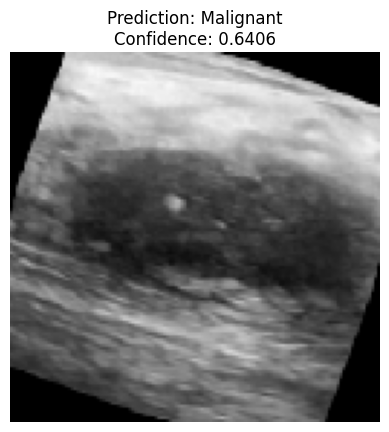

Prediction result:
Predicted class: Malignant
Probability: 0.6406
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step
Validation set metrics:
Accuracy : 0.9356
Precision: 0.9453
Recall   : 0.9075
F1-score : 0.9260
AUC      : 0.9817


In [13]:
# Test image path
img_path = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val/malignant/"
    "malignant (1)-rotated1-rotated1-rotated1.png"
)

# Image preprocessing
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0  # Normalize pixel values

# Prediction
pred_prob = model.predict(img_array)[0][0]
pred_class = "Malignant" if pred_prob > 0.5 else "Benign"

# Visualization
plt.imshow(img)
plt.title(f"Prediction: {pred_class}\nConfidence: {pred_prob:.4f}")
plt.axis("off")
plt.show()

print("Prediction result:")
print(f"Predicted class: {pred_class}")
print(f"Probability: {pred_prob:.4f}")

# Recalculate predictions on the entire validation set
y_true, y_pred_prob = [], []

for images, labels in val_gen:
    probs = model.predict(images).flatten()
    y_pred_prob.extend(probs)
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)
y_pred = (y_pred_prob > 0.5).astype(int)

# Evaluation metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_pred_prob)

print("Validation set metrics:")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


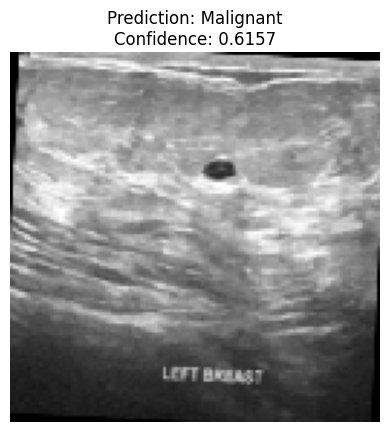

Prediction result:
Predicted class: Malignant
Probability: 0.6157
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Validation set metrics:
Accuracy : 0.9356
Precision: 0.9453
Recall   : 0.9075
F1-score : 0.9260
AUC      : 0.9817


In [14]:
# Test image path
img_path = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val/benign/"
    "benign (1)-rotated1.png"
)

# Image preprocessing
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0  # Normalize pixel values

# Prediction
pred_prob = model.predict(img_array)[0][0]
pred_class = "Malignant" if pred_prob > 0.5 else "Benign"

# Visualization
plt.imshow(img)
plt.title(f"Prediction: {pred_class}\nConfidence: {pred_prob:.4f}")
plt.axis("off")
plt.show()

print("Prediction result:")
print(f"Predicted class: {pred_class}")
print(f"Probability: {pred_prob:.4f}")

# Recalculate predictions on the entire validation set
y_true, y_pred_prob = [], []

for images, labels in val_gen:
    probs = model.predict(images).flatten()
    y_pred_prob.extend(probs)
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)
y_pred = (y_pred_prob > 0.5).astype(int)

# Evaluation metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_pred_prob)

print("Validation set metrics:")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")


# Section B) Machine learning

In [20]:
import os
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Display library versions
print("TensorFlow version:", tf.__version__)
print("XGBoost version:", xgb.__version__)


TensorFlow version: 2.18.0
XGBoost version: 2.0.3


In [21]:
# Dataset paths
base_dir = "/kaggle/input/ultrasound-breast-images-for-breast-cancer/ultrasound breast classification"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")

# Parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 64

# Data preprocessing and normalization
datagen = ImageDataGenerator(rescale=1.0 / 255)

# Training set generator
train_gen = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

# Validation set generator
val_gen = datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 8116 images belonging to 2 classes.
Found 900 images belonging to 2 classes.


In [22]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
import tensorflow as tf

# Base model for feature extraction
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Add global average pooling to obtain compact feature vectors
x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
feature_extractor = Model(inputs=base_model.input, outputs=x)

# Extract features from training and validation sets
X_train = feature_extractor.predict(train_gen, verbose=1)
X_val = feature_extractor.predict(val_gen, verbose=1)

# Extract corresponding labels
y_train = train_gen.classes
y_val = val_gen.classes

print(f"Training features: {X_train.shape}, Labels: {y_train.shape}")
print(f"Validation features: {X_val.shape}, Labels: {y_val.shape}")

127/127 ━━━━━━━━━━━━━━━━━━━━ 40s 270ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 410ms/step
Training features: (8116, 1280), Labels: (8116,)
Validation features: (900, 1280), Labels: (900,)


# Model 1 - PCA

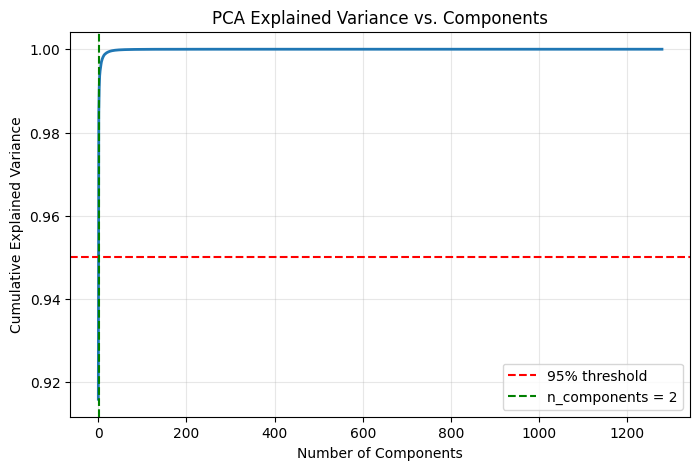

Optimal number of components: 2


In [24]:
from sklearn.decomposition import PCA

def find_optimal_pca_components(X, variance_threshold=0.95, plot=True):
    """
    Finds the optimal number of PCA components required to retain a given amount of variance.

    Parameters
    ----------
    X : np.ndarray
        Input feature matrix for PCA.
    variance_threshold : float, optional (default=0.95)
        The cumulative explained variance ratio threshold (e.g., 0.95 for 95% variance).
    plot : bool, optional (default=True)
        Whether to display the explained variance plot.

    Returns
    -------
    optimal_components : int
        The smallest number of components needed to reach the target variance.
    pca_model : PCA
        The fitted PCA model.
    """
    # Fit PCA without specifying n_components
    pca = PCA().fit(X)
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

    # Find the smallest number of components that meets the target variance
    optimal_components = np.argmax(cumulative_variance >= variance_threshold) + 1

    if plot:
        plt.figure(figsize=(8, 5))
        plt.plot(cumulative_variance, linewidth=2)
        plt.axhline(y=variance_threshold, color='r', linestyle='--', label=f"{variance_threshold*100:.0f}% threshold")
        plt.axvline(x=optimal_components, color='g', linestyle='--', label=f"n_components = {optimal_components}")
        plt.xlabel("Number of Components")
        plt.ylabel("Cumulative Explained Variance")
        plt.title("PCA Explained Variance vs. Components")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

    return optimal_components, pca

optimal_n, pca_model = find_optimal_pca_components(X_train, variance_threshold=0.95)
print(f"Optimal number of components: {optimal_n}")

In [26]:
from sklearn.decomposition import PCA

# Example: PCA with additional configuration
pca = PCA(
    n_components=optimal_n,      # Number of principal components to retain
    svd_solver='auto',           # Solver: 'auto', 'full', 'arpack', or 'randomized'
    whiten=False,                # If True, decorrelates features (can help for some ML models)
    random_state=42,             # Ensures reproducibility for 'randomized' solver
    copy=True,                   # If False, the input data X will be overwritten during fitting
    tol=0.0                      # Tolerance for convergence (useful for large datasets)
)

# Fit PCA on training data and transform both sets
X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)

print("Reduced feature dimensions:", X_train_pca.shape)
print(f"Explained variance ratio (first 10 components): {pca.explained_variance_ratio_[:10]}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.4f}")


Reduced feature dimensions: (8116, 2)
Explained variance ratio (first 10 components): [0.9159549  0.06863725]
Total explained variance: 0.9846


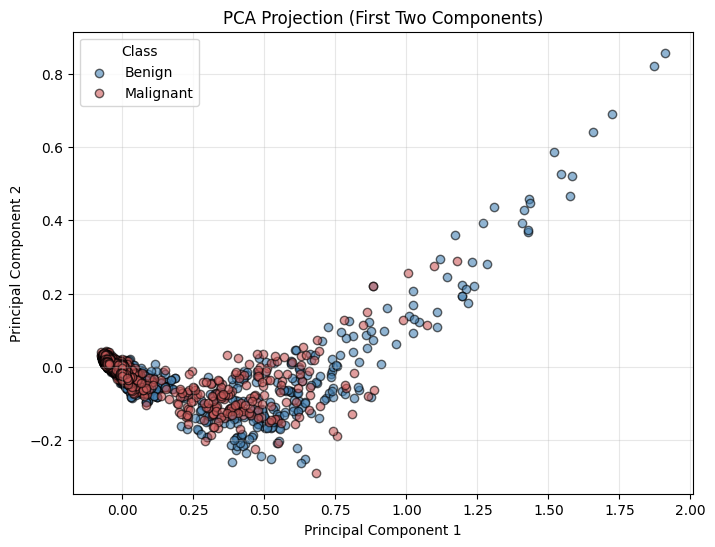

In [27]:
# Define colors and labels
colors = ['steelblue', 'indianred']
labels = ['Benign', 'Malignant']

# Plot PCA projection
plt.figure(figsize=(8, 6))
for i, label in enumerate(np.unique(y_train)):
    plt.scatter(
        X_train_pca[y_train == label, 0],
        X_train_pca[y_train == label, 1],
        label=labels[i],
        alpha=0.6,
        edgecolor="k",
        color=colors[i]
    )

plt.title("PCA Projection (First Two Components)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Class")
plt.grid(True, alpha=0.3)
plt.show()

# Model 3 - t-SNE

In [31]:
from sklearn.manifold import TSNE

# Configure t-SNE
tsne = TSNE(
    n_components=2,          # Project to 2D space
    perplexity=100,           # Balance between local and global structure
    learning_rate=200,       # Typical range: 10–1000
    n_iter=1000,             # Number of optimization iterations
    random_state=42,         # Reproducibility
    init='pca',              # Better initialization than random
    verbose=1
)

# Fit and transform (can be done on a subset for speed)
sample_size = min(2000, len(X_val))  # limit to avoid memory overload
X_sample = X_val[:sample_size]
y_sample = y_val[:sample_size]

X_tsne = tsne.fit_transform(X_sample)
print(f"t-SNE output shape: {X_tsne.shape}")

[t-SNE] Computing 301 nearest neighbors...
[t-SNE] Indexed 900 samples in 0.001s...
[t-SNE] Computed neighbors for 900 samples in 0.065s...
[t-SNE] Computed conditional probabilities for sample 900 / 900
[t-SNE] Mean sigma: 0.011436
[t-SNE] KL divergence after 250 iterations with early exaggeration: 49.737263
[t-SNE] KL divergence after 1000 iterations: 0.354511
t-SNE output shape: (900, 2)


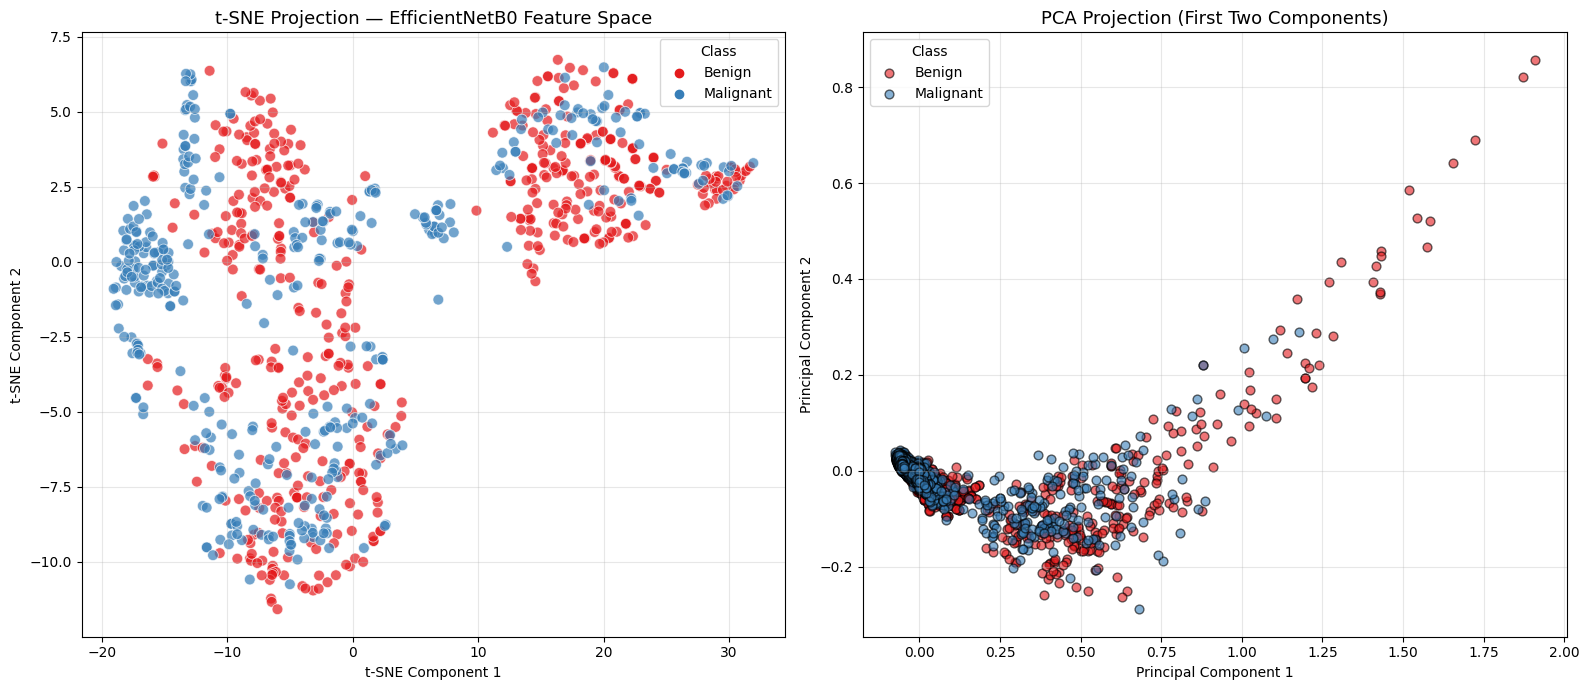

In [33]:
# Prepare class labels
labels = ["Benign" if label == 0 else "Malignant" for label in y_sample]
colors = sns.color_palette("Set1", 2)

# Create subplot grid
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# t-SNE Projection
sns.scatterplot(
    ax=axes[0],
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=labels,
    palette=colors,
    alpha=0.7,
    s=60
)
axes[0].set_title("t-SNE Projection — EfficientNetB0 Feature Space", fontsize=13)
axes[0].set_xlabel("t-SNE Component 1")
axes[0].set_ylabel("t-SNE Component 2")
axes[0].grid(alpha=0.3)
axes[0].legend(title="Class")

# PCA Projection
for i, label in enumerate(np.unique(y_train)):
    axes[1].scatter(
        X_train_pca[y_train == label, 0],
        X_train_pca[y_train == label, 1],
        label=["Benign", "Malignant"][i],
        color=colors[i],
        alpha=0.6,
        edgecolor="k",
        s=40
    )
axes[1].set_title("PCA Projection (First Two Components)", fontsize=13)
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].grid(alpha=0.3)
axes[1].legend(title="Class")

# Adjust layout
plt.tight_layout()
plt.show()

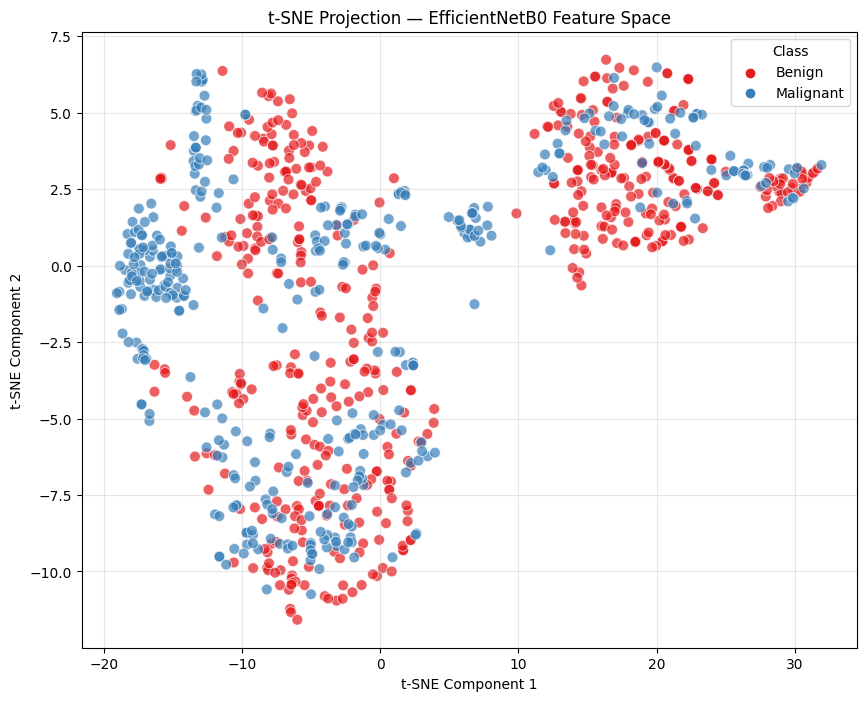

In [32]:
# Plot the 2D projection
plt.figure(figsize=(10, 8))
palette = sns.color_palette("Set1", 2)
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=["Benign" if label == 0 else "Malignant" for label in y_sample],
    palette=palette,
    alpha=0.7,
    s=60
)
plt.title("t-SNE Projection — EfficientNetB0 Feature Space")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="Class", loc="best")
plt.grid(alpha=0.3)
plt.show()

# Model 4 - XGBoost

In [34]:
import xgboost as xgb
import joblib

# XGBoost parameters for GPU training
params = {
    "tree_method": "hist",
    "device": "cuda",
    "max_bin": 128,
    "max_depth": 6,
    "eta": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "binary:logistic",
    "eval_metric": "auc"
}

# Create DMatrix objects for XGBoost
dtrain = xgb.DMatrix(X_train_pca, label=y_train)
dval = xgb.DMatrix(X_val_pca, label=y_val)

# Train the model with early stopping
xgb_model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=400,
    evals=[(dtrain, "train"), (dval, "eval")],
    early_stopping_rounds=20,
    verbose_eval=25
)

# Save trained model and PCA transformer
xgb_model.save_model("xgboost_ultrasound_gpu.model")
joblib.dump(pca, "pca_ultrasound.pkl")

print("Model and PCA saved successfully.")

[0]	train-auc:0.73875	eval-auc:0.70130
[25]	train-auc:0.76065	eval-auc:0.70894
[50]	train-auc:0.76433	eval-auc:0.71118
[75]	train-auc:0.76600	eval-auc:0.71177
[100]	train-auc:0.76713	eval-auc:0.71150
[101]	train-auc:0.76716	eval-auc:0.71181
Model and PCA saved successfully.


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:160: UserWarning: [00:42:47] WARNING: /workspace/src/c_api/c_api.cc:1240: Saving into deprecated binary model format, please consider using `json` or `ubj`. Model format will default to JSON in XGBoost 2.2 if not specified.
  warnings.warn(smsg, UserWarning)


In [35]:
# Generate predictions using the trained XGBoost model
y_prob = xgb_model.predict(dval)

# Convert probabilities to binary class predictions
y_pred = (y_prob > 0.5).astype(int)

Transformed validation shape: (900, 2)


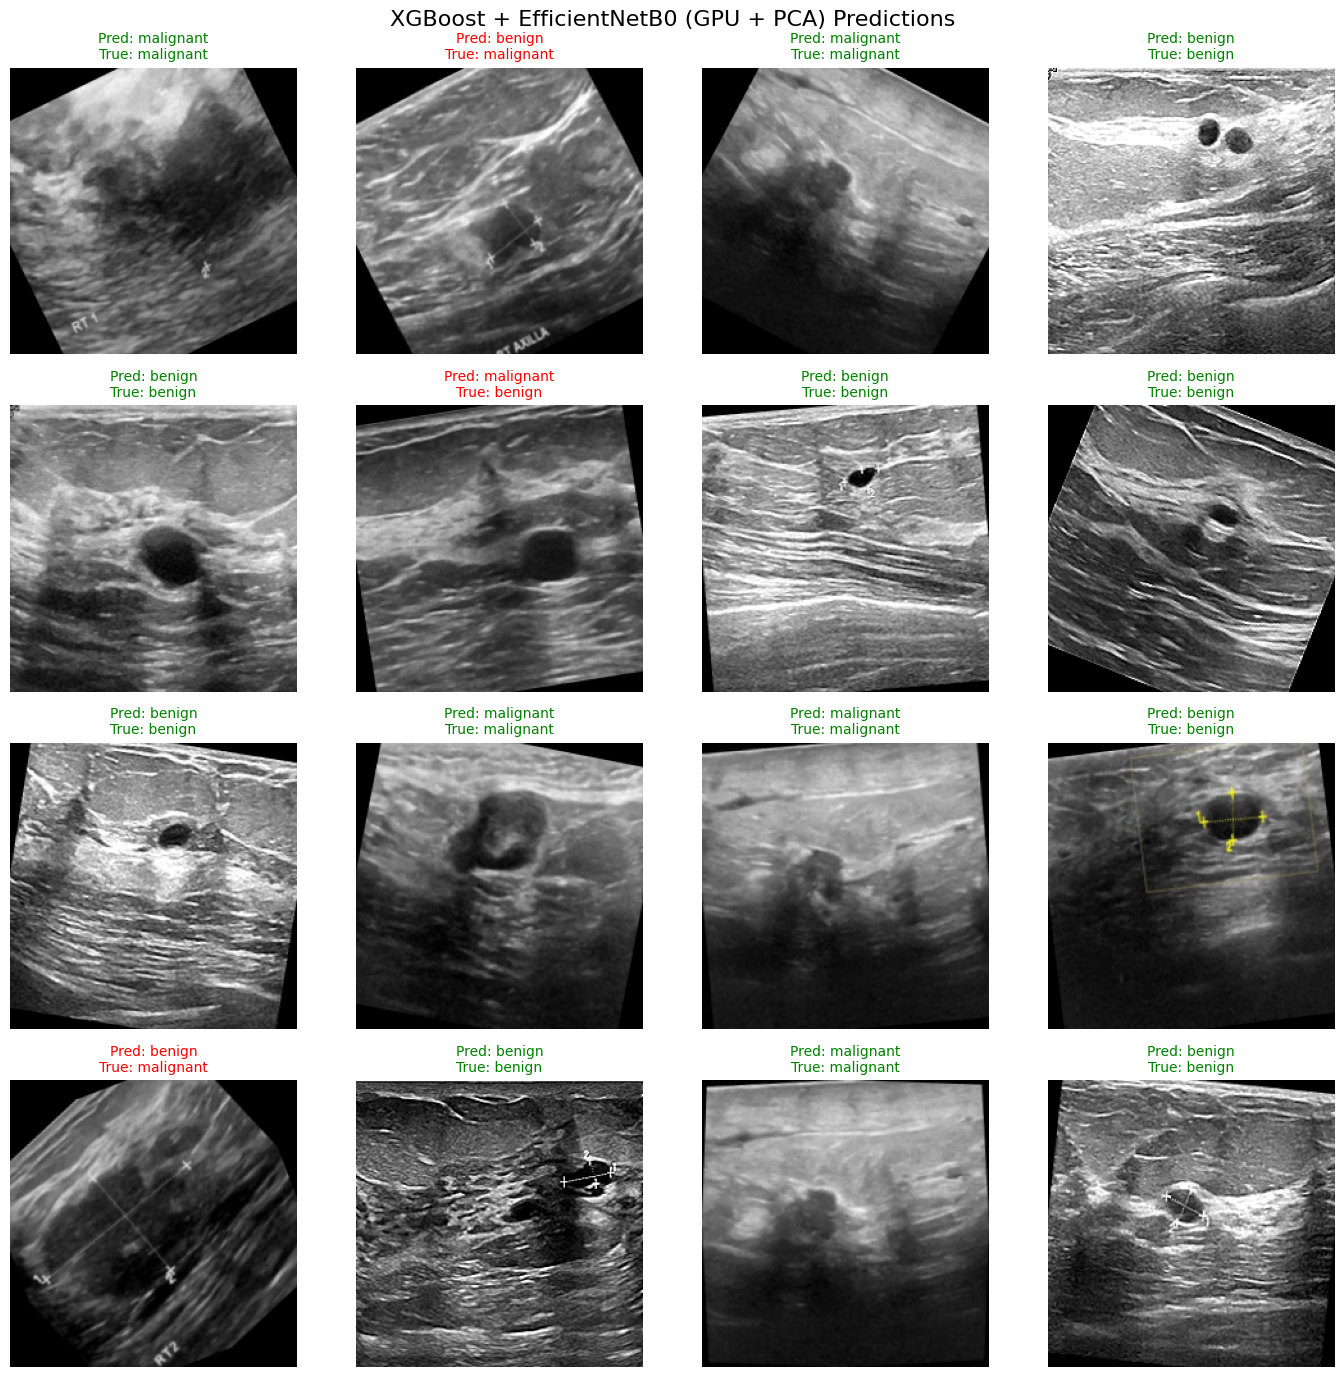

In [37]:
# Load the PCA transformer if saved
# pca = joblib.load("pca_ultrasound.pkl")

# Apply the same PCA transformation used during training
X_val_pca = pca.transform(X_val)
print("Transformed validation shape:", X_val_pca.shape)

# Generate predictions using the trained XGBoost model
y_prob = xgb_model.predict(xgb.DMatrix(X_val_pca))
y_pred = (y_prob > 0.5).astype(int)

# Class labels
class_names = list(val_gen.class_indices.keys())

# Randomly select 16 samples for visualization
n = 16
indices = random.sample(range(len(y_val)), n)

# Plot results
plt.figure(figsize=(14, 14))
for i, idx in enumerate(indices):
    plt.subplot(4, 4, i + 1)
    img_path = val_gen.filepaths[idx]
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    plt.imshow(img)

    true_label = class_names[y_val[idx]]
    pred_label = class_names[y_pred[idx]]
    color = "green" if true_label == pred_label else "red"

    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color, fontsize=10)
    plt.axis("off")

plt.suptitle("XGBoost + EfficientNetB0 (GPU + PCA) Predictions", fontsize=16)
plt.tight_layout()
plt.show()

In [39]:
# Saved model path
xgb_path = "/kaggle/working/xgboost_ultrasound_gpu.model"
pca_path = "/kaggle/working/pca_ultrasound.pkl"

# Load the XGBoost model
xgb_model = xgb.Booster()
xgb_model.load_model(xgb_path)

# Load PCA (required if you used PCA before training)
pca = joblib.load(pca_path)

# Create the EfficientNetB0 feature extractor (without the classification head)
feature_extractor = EfficientNetB0(
weights='imagenet',
include_top=False,
input_shape=(224, 224, 3)
)
feature_extractor.trainable = False

# Add global pooling (for feature vector) 1280-D)
global_avg_layer = tf.keras.layers.GlobalAveragePooling2D()

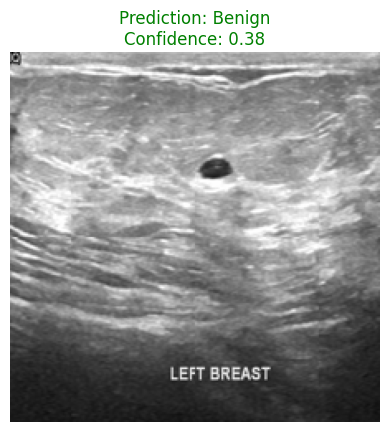

Predicted class: Benign
Confidence score: 0.3801


In [43]:
def predict_image_xgboost(img_path):
    """Predict the class (Benign or Malignant) of a breast ultrasound image
    using EfficientNetB0 feature extraction, PCA reduction, and XGBoost classifier.
    """

    # Load and preprocess the image
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Extract convolutional features from EfficientNetB0
    features = feature_extractor.predict(img_array, verbose=0)

    # Apply global average pooling (same as during training)
    features = global_avg_layer(features).numpy()  # shape: (1, 1280)

    # Apply PCA transformation (same PCA used during training)
    features_pca = pca.transform(features)

    # Predict with XGBoost
    dmatrix = xgb.DMatrix(features_pca)
    prob = xgb_model.predict(dmatrix)[0]
    pred = int(prob > 0.5)

    # Return class label and probability
    label = "Malignant" if pred == 1 else "Benign"
    return label, prob

image_path = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val/benign/benign (1).png"
)

label, prob = predict_image_xgboost(image_path)

# Visualization
img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
plt.imshow(img)
plt.axis("off")
color = "green" if label == "Benign" else "red"
plt.title(f"Prediction: {label}\nConfidence: {prob:.2f}", color=color, fontsize=12)
plt.show()

print(f"Predicted class: {label}")
print(f"Confidence score: {prob:.4f}")

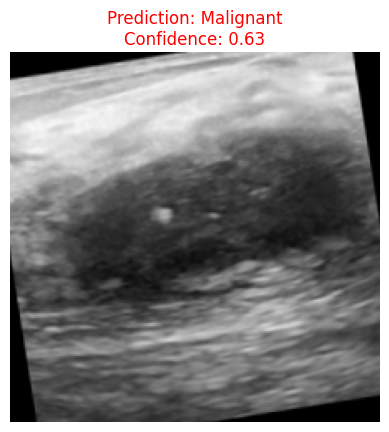

Predicted class: Malignant
Confidence: 0.6286


In [45]:
# Prediction function
def predict_image_xgboost(img_path):
    """Predict the class (Benign or Malignant) of a breast ultrasound image
    using EfficientNetB0 feature extraction, PCA reduction, and XGBoost classifier.
    """

    # Load and preprocess the image
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Extract convolutional features from EfficientNetB0
    features = feature_extractor.predict(img_array, verbose=0)

    # Apply global average pooling (same as during training)
    features = global_avg_layer(features).numpy()  # shape: (1, 1280)

    # Apply PCA transformation (same PCA used during training)
    features_pca = pca.transform(features)

    # Predict with XGBoost
    dmatrix = xgb.DMatrix(features_pca)
    prob = xgb_model.predict(dmatrix)[0]
    pred = int(prob > 0.5)

    # Return class label and probability
    label = "Malignant" if pred == 1 else "Benign"
    return label, prob


# Path to the test image
image_path = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val/malignant/"
    "malignant (1)-rotated1-rotated2-rotated32.png"
)

# Perform prediction
label, prob = predict_image_xgboost(image_path)

# Display image and result
img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
plt.imshow(img)
plt.axis("off")
color = "green" if label == "Benign" else "red"
plt.title(f"Prediction: {label}\nConfidence: {prob:.2f}", color=color, fontsize=12)
plt.show()

# Print textual output
print(f"Predicted class: {label}")
print(f"Confidence: {prob:.4f}")

In [46]:
# Compute model evaluation metrics
auc = roc_auc_score(y_val, y_prob)
cm = confusion_matrix(y_val, y_pred)

print(f"AUC Score: {auc:.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred, target_names=["Benign", "Malignant"]))

AUC Score: 0.7118

Classification Report:
              precision    recall  f1-score   support

      Benign       0.68      0.76      0.72       500
   Malignant       0.65      0.55      0.60       400

    accuracy                           0.67       900
   macro avg       0.66      0.66      0.66       900
weighted avg       0.66      0.67      0.66       900



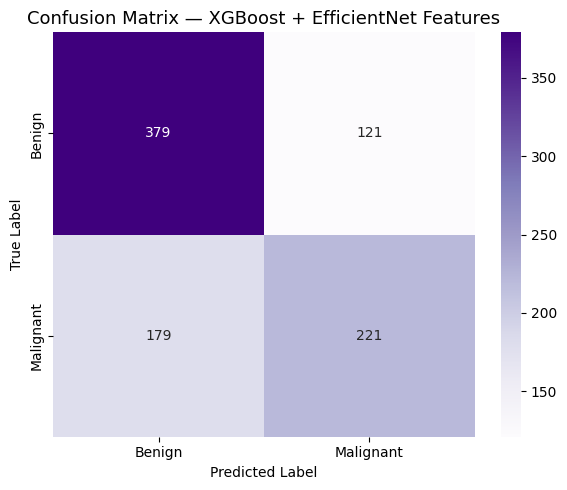

In [47]:
# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)
plt.title("Confusion Matrix — XGBoost + EfficientNet Features", fontsize=13)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

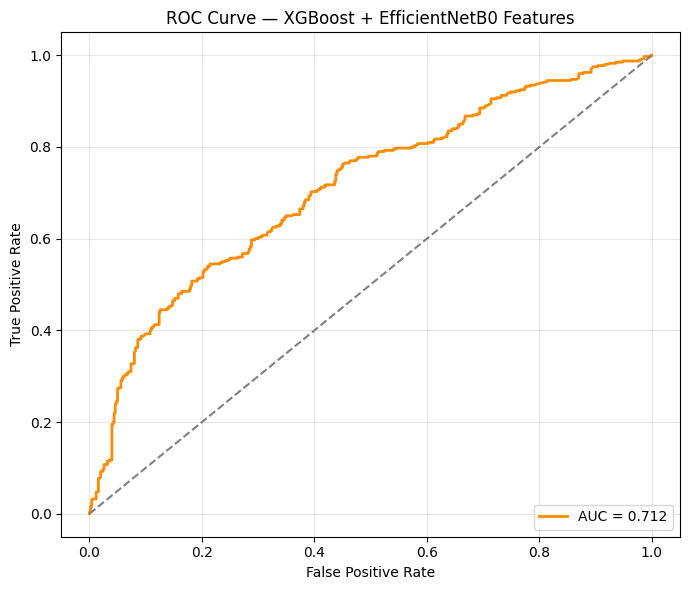

In [48]:
from sklearn.metrics import roc_curve, auc as calc_auc
from sklearn.metrics import auc

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(y_val, y_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — XGBoost + EfficientNetB0 Features")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Model 5 - Random Forest

In [49]:
!apt-get install graphviz
!pip install graphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 132 not upgraded.


In [50]:
import tensorflow as tf
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc

In [51]:
# Dataset paths
base_dir = "/kaggle/input/ultrasound-breast-images-for-breast-cancer/ultrasound breast classification"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")

# Parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 64

# Data generators with rescaling
datagen = ImageDataGenerator(rescale=1.0 / 255)

#
train_gen = datagen.flow_from_directory(train_dir,
                                        target_size=IMG_SIZE,
                                        batch_size=BATCH_SIZE,
                                        class_mode="binary",
                                        shuffle=False)

#
val_gen = datagen.flow_from_directory(val_dir,
                                      target_size=IMG_SIZE,
                                      batch_size=BATCH_SIZE,
                                      class_mode="binary",
                                      shuffle=False)

# Base model — EfficientNetB0 pretrained on ImageNet
base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Global average pooling to obtain feature vectors
x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
feature_extractor = Model(inputs=base_model.input, outputs=x)

# Feature extraction
X_train = feature_extractor.predict(train_gen, verbose=1)
y_train = train_gen.classes
X_val = feature_extractor.predict(val_gen, verbose=1)
y_val = val_gen.classes

print("Feature extraction completed.")
print(f"Training features: {X_train.shape}, Validation features: {X_val.shape}")

Found 8116 images belonging to 2 classes.
Found 900 images belonging to 2 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


127/127 ━━━━━━━━━━━━━━━━━━━━ 40s 268ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 411ms/step
Feature extraction completed.
Training features: (8116, 1280), Validation features: (900, 1280)


In [52]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest model definition
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Model training
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=12, n_estimators=300, n_jobs=-1,
                       random_state=42)

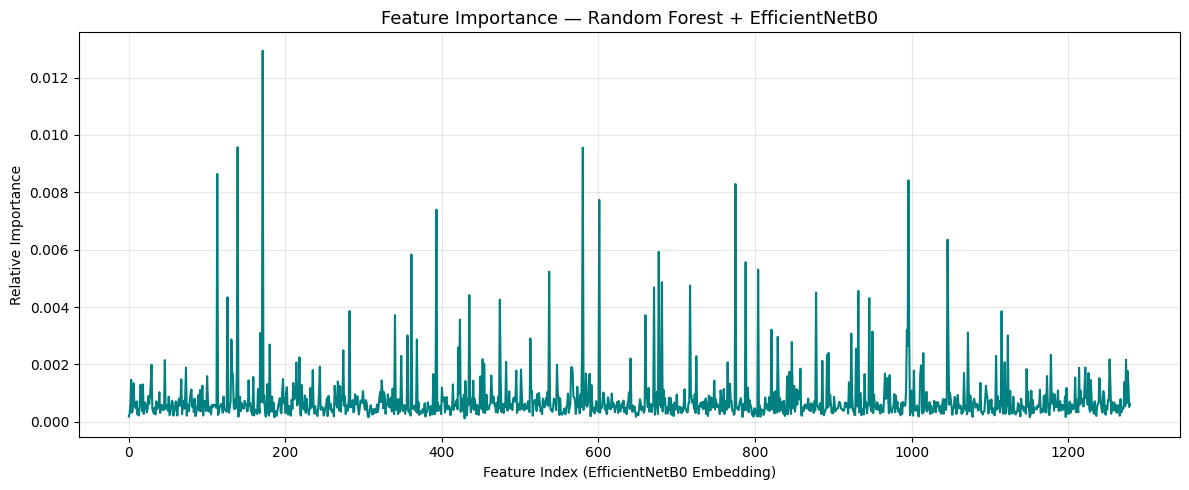

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


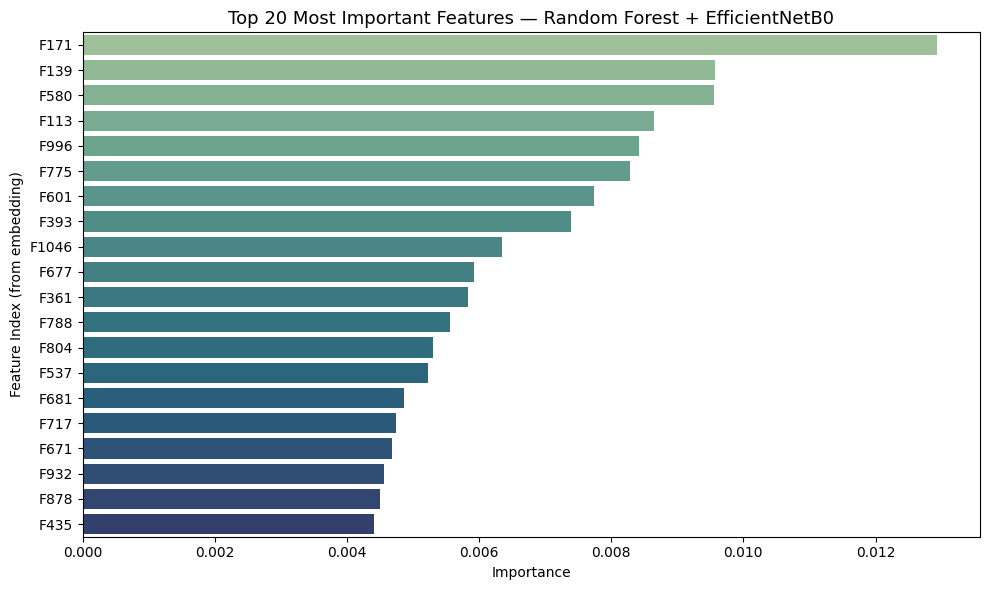

In [53]:
# Feature importance values
importances = rf_model.feature_importances_

# Line plot of all feature importances
plt.figure(figsize=(12, 5))
plt.plot(importances, color="teal")
plt.title("Feature Importance — Random Forest + EfficientNetB0", fontsize=13)
plt.xlabel("Feature Index (EfficientNetB0 Embedding)")
plt.ylabel("Relative Importance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Top 20 most important features
indices = np.argsort(importances)[::-1][:20]
top_features = importances[indices]

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features, y=[f"F{i}" for i in indices], palette="crest")
plt.title("Top 20 Most Important Features — Random Forest + EfficientNetB0", fontsize=13)
plt.xlabel("Importance")
plt.ylabel("Feature Index (from embedding)")
plt.tight_layout()
plt.show()

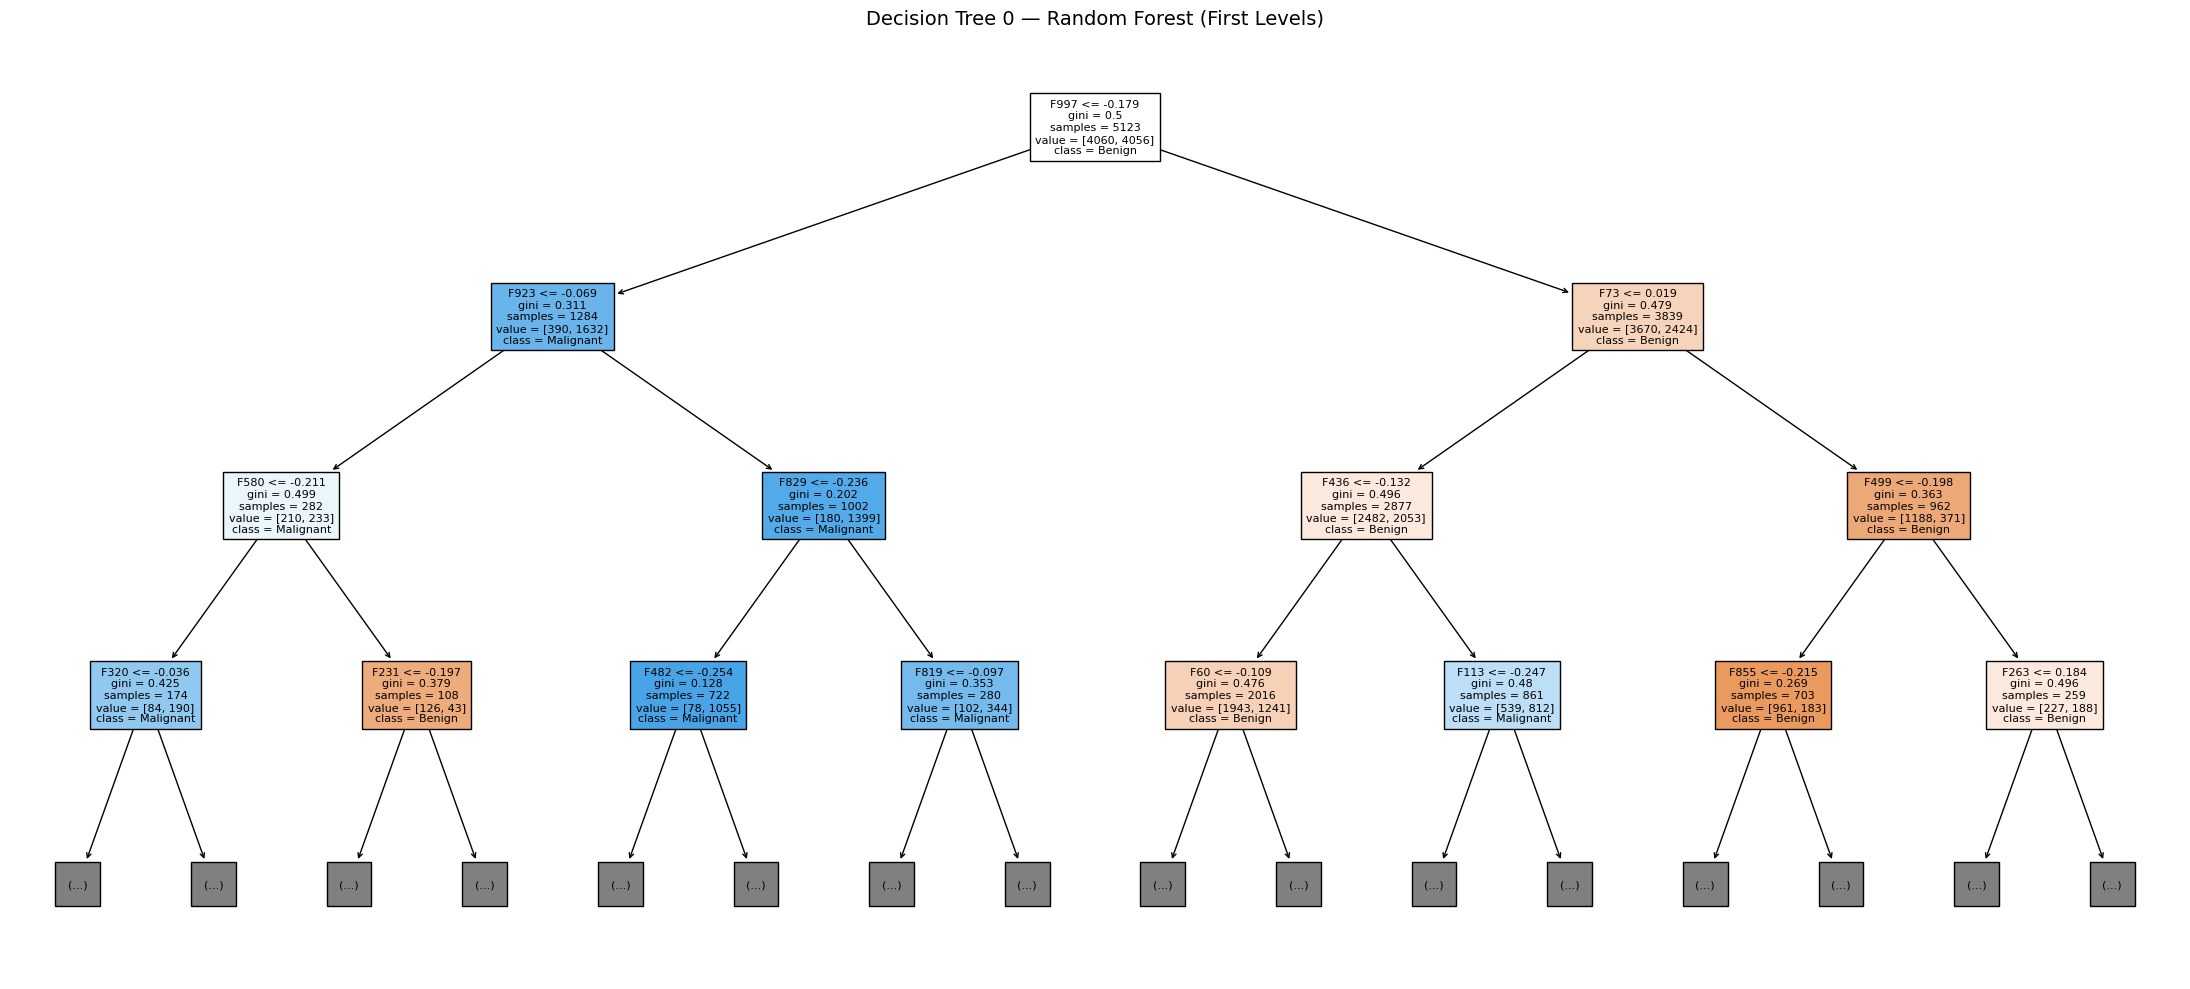

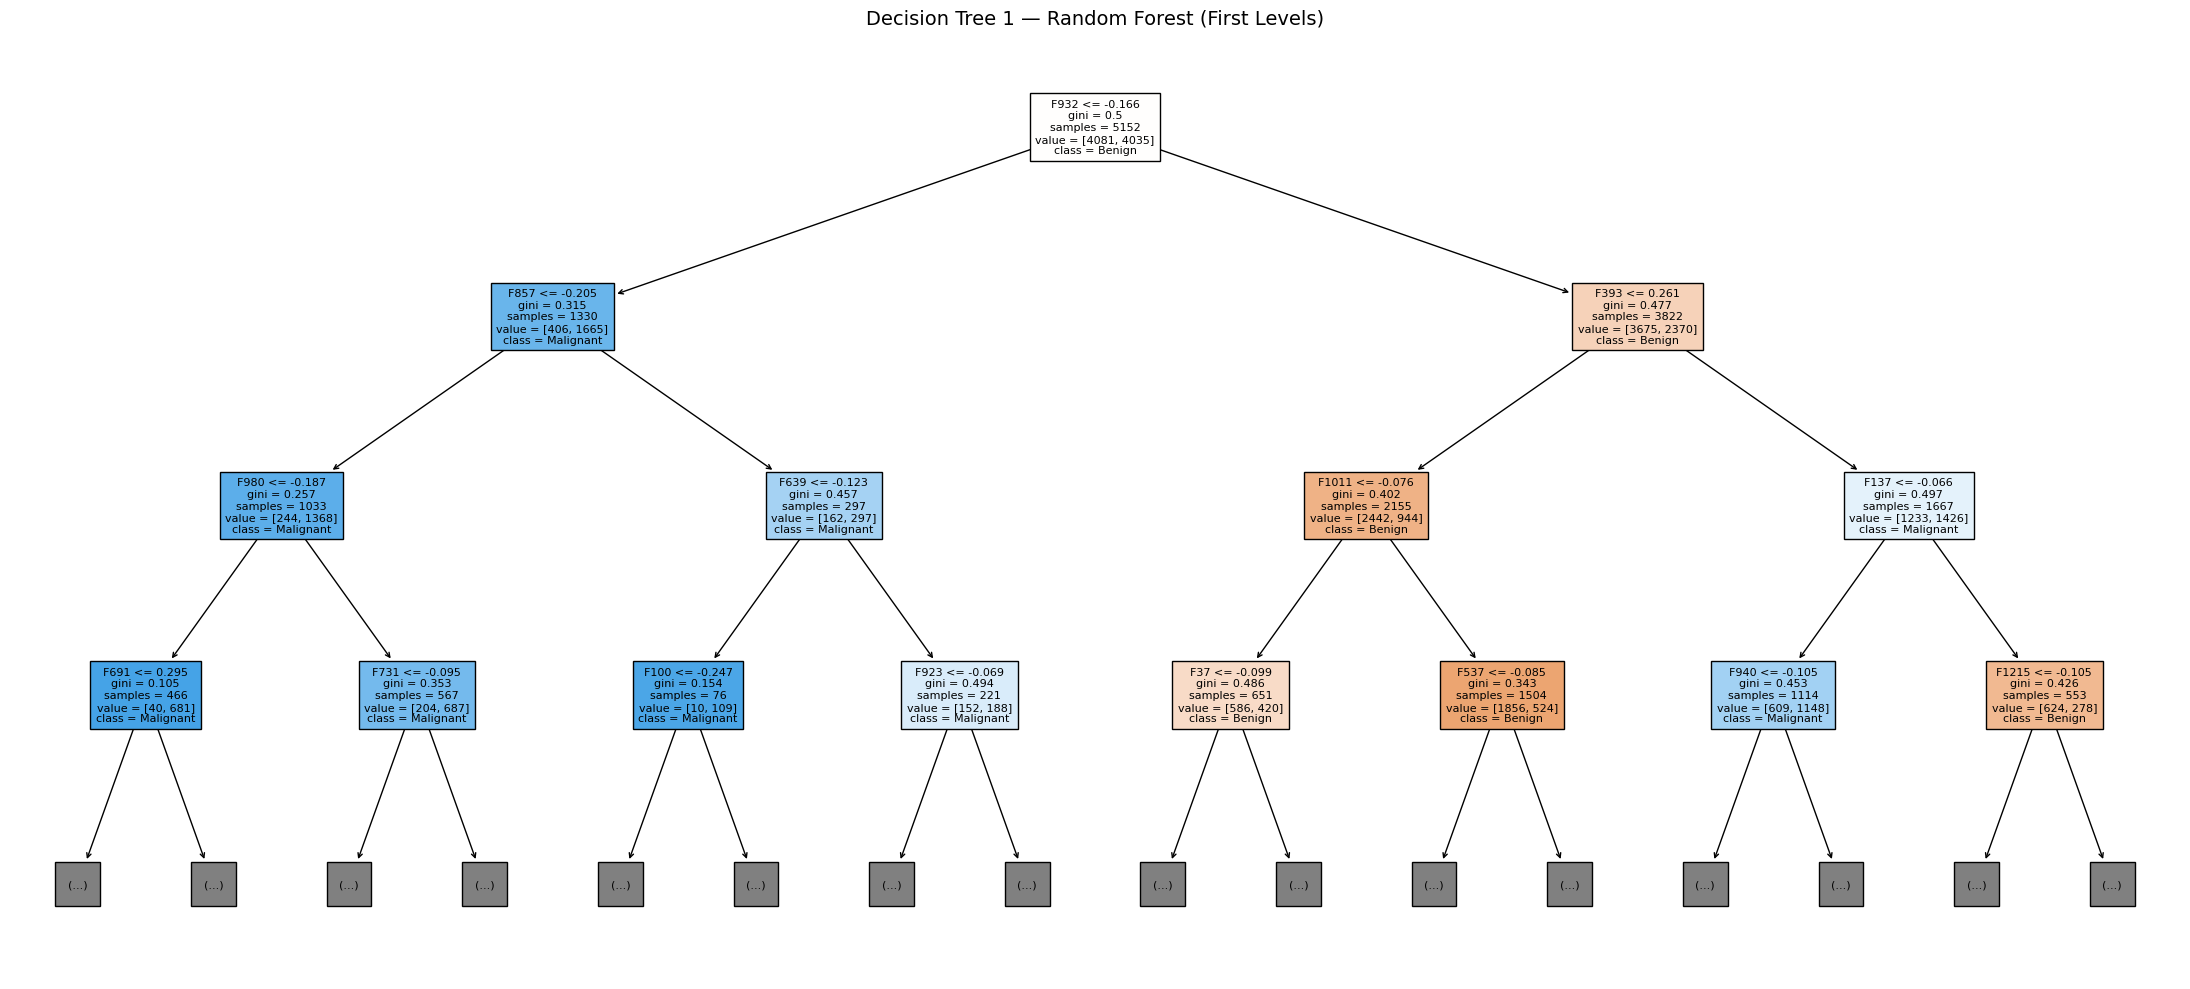

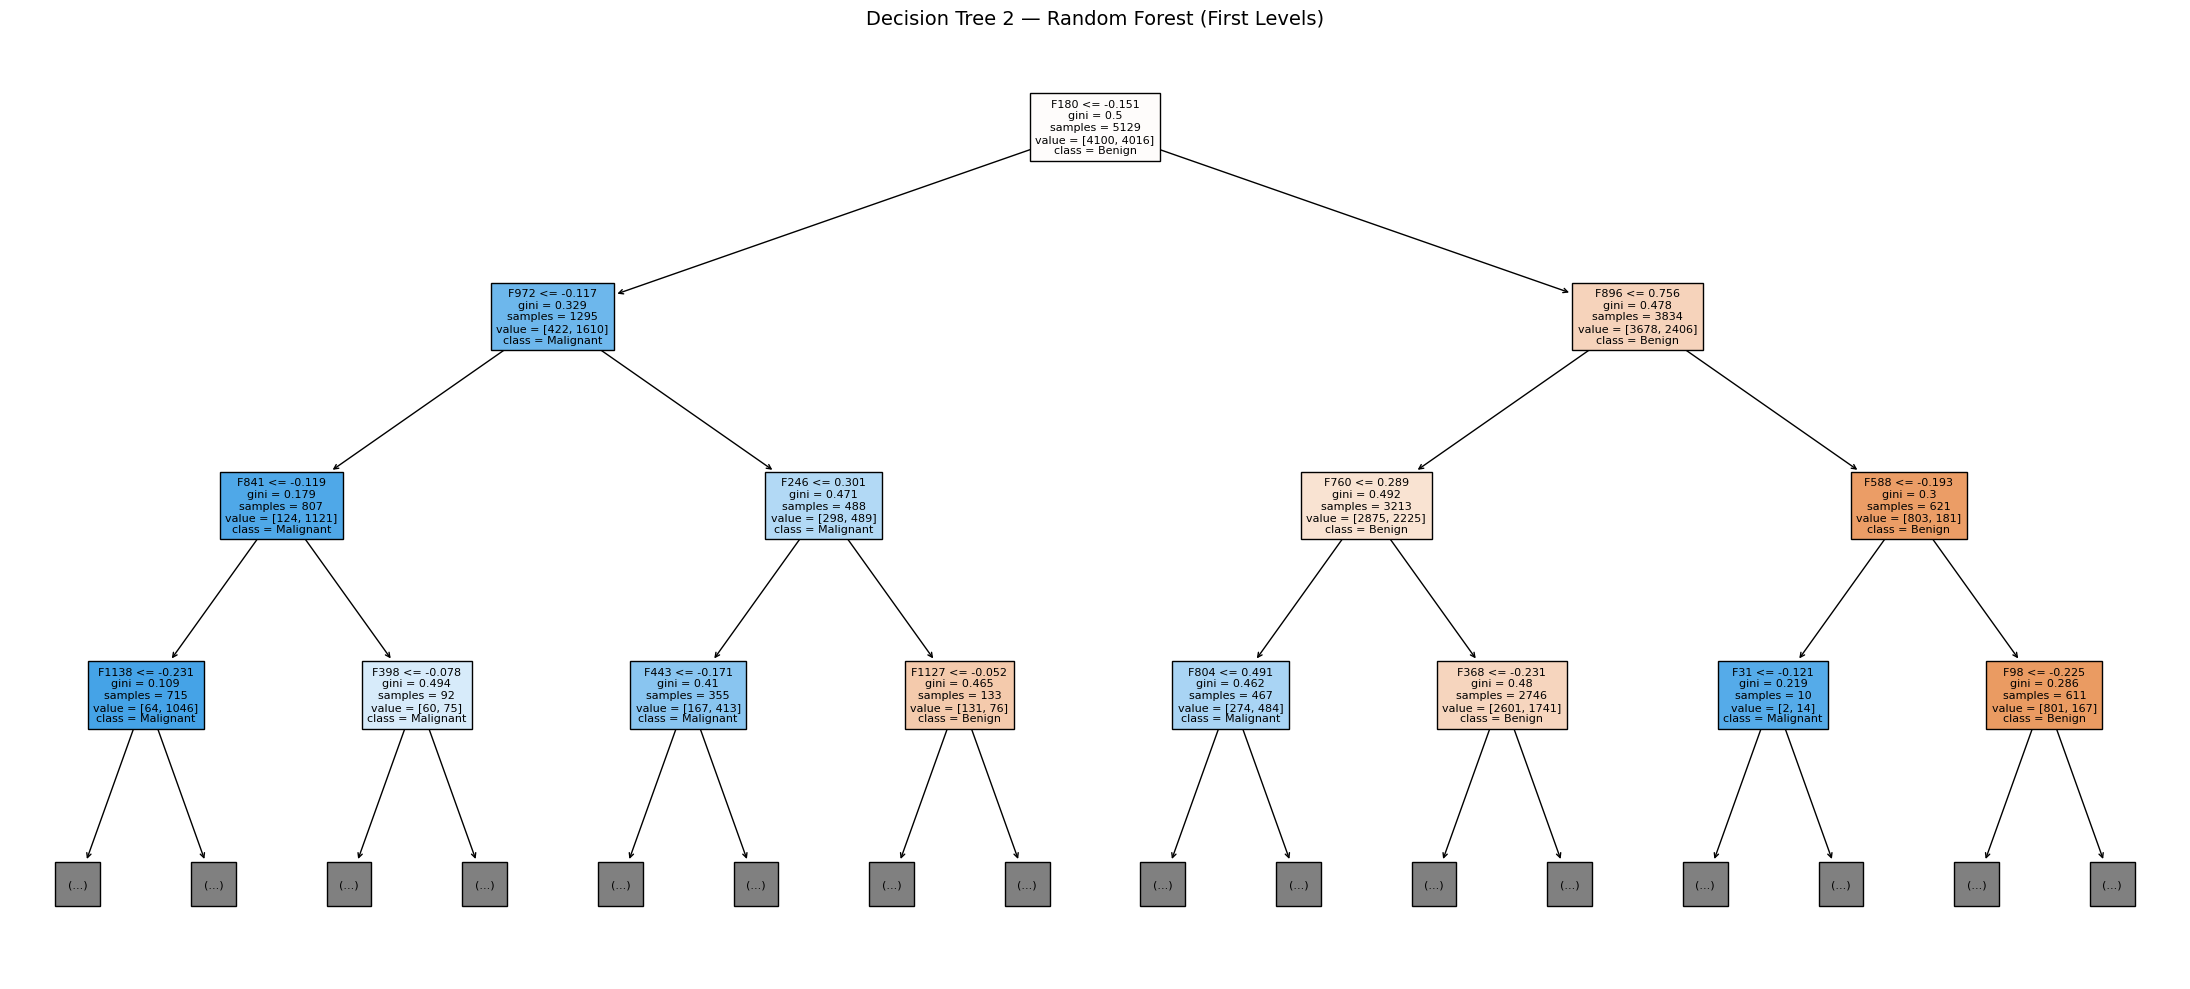

In [54]:
import graphviz
from sklearn.tree import export_graphviz, plot_tree

# Display a few trees from the Random Forest
n_trees = 3

for i in range(n_trees):
    plt.figure(figsize=(22, 10))
    plot_tree(
        rf_model.estimators_[i],
        feature_names=[f"F{j}" for j in range(X_train.shape[1])],
        class_names=["Benign", "Malignant"],
        filled=True,
        max_depth=3,
        fontsize=8
    )
    plt.title(f"Decision Tree {i} — Random Forest (First Levels)", fontsize=14)
    plt.tight_layout()
    plt.show()


In [55]:
# Generate predictions and probabilities
y_pred = rf_model.predict(X_val)
y_prob = rf_model.predict_proba(X_val)[:, 1]

# Save trained model
joblib.dump(rf_model, "randomforest_ultrasound.model")
print("Random Forest model saved: randomforest_ultrasound.model")

Random Forest model saved: randomforest_ultrasound.model


In [56]:
# Compute primary evaluation metrics
accuracy = (y_val == y_pred).mean()
auc_score = roc_auc_score(y_val, y_prob)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUC Score: {auc_score:.4f}")

Accuracy: 0.8278
AUC Score: 0.8978


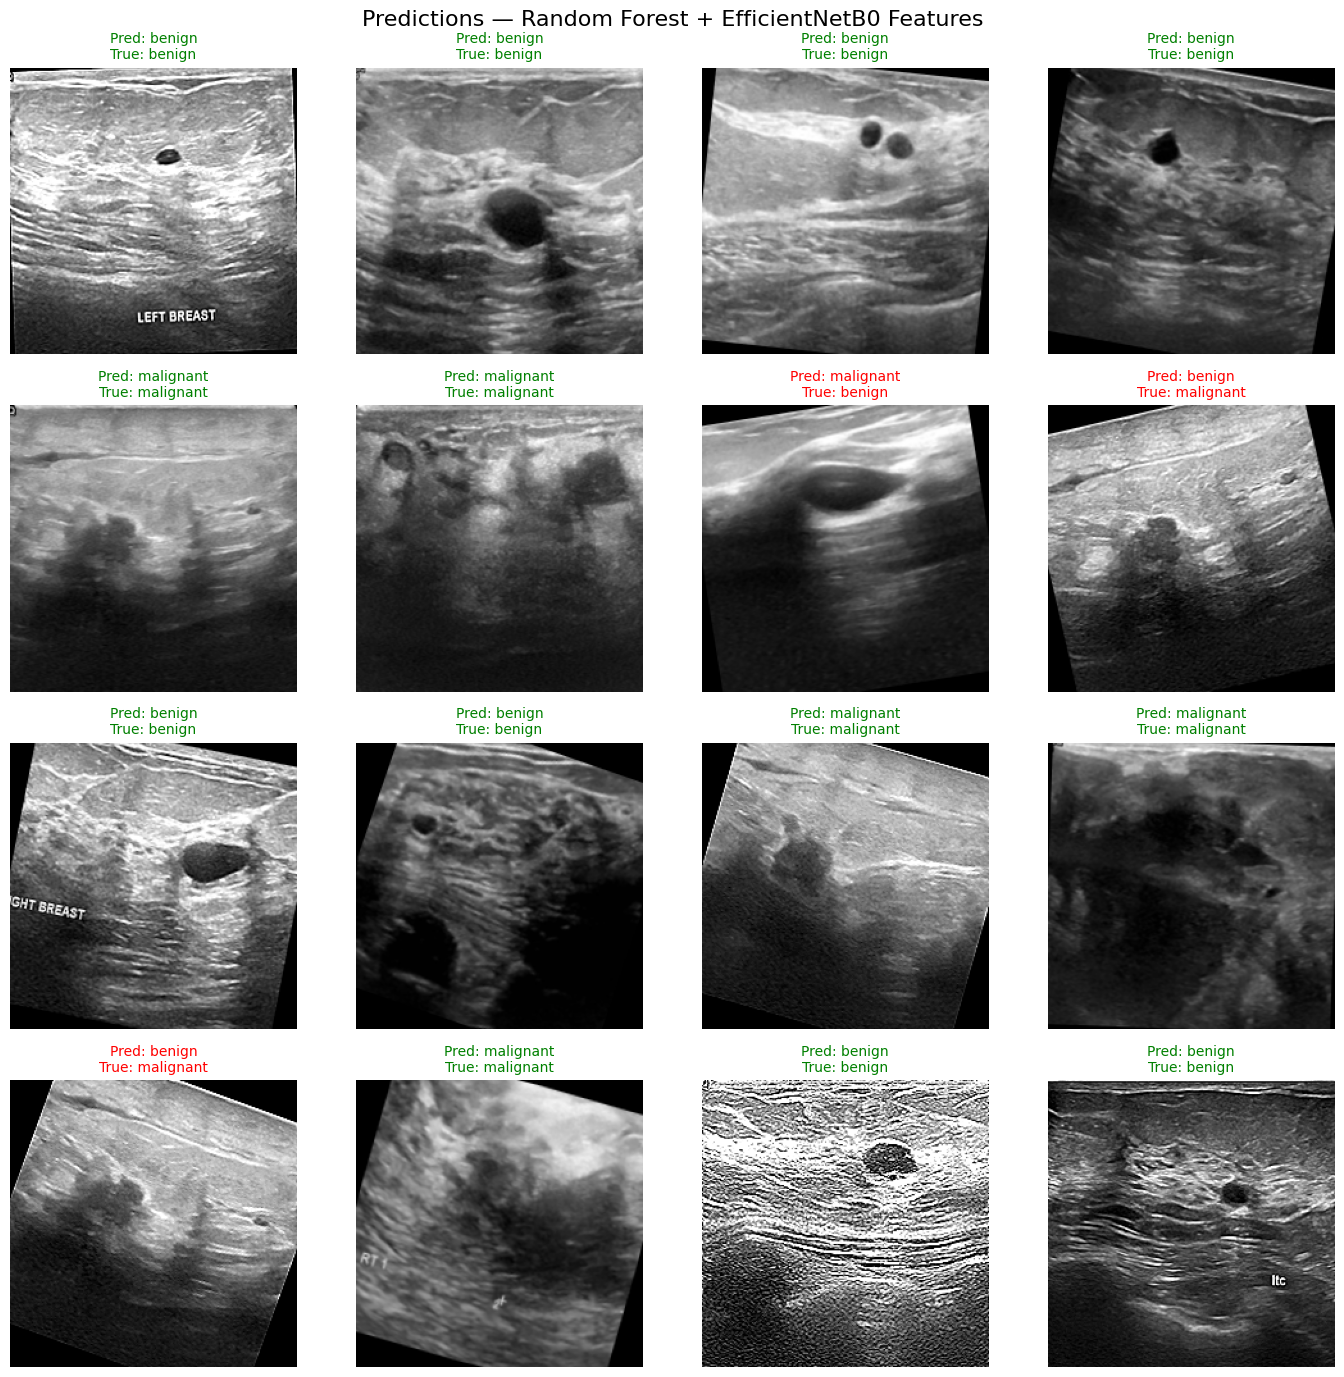

In [57]:
# Visualization of Random Forest predictions
class_names = list(val_gen.class_indices.keys())
n_samples = 16
indices = random.sample(range(len(y_val)), n_samples)

plt.figure(figsize=(14, 14))
for i, idx in enumerate(indices):
    plt.subplot(4, 4, i + 1)
    img_path = val_gen.filepaths[idx]
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    plt.imshow(img)

    true_label = class_names[y_val[idx]]
    pred_label = class_names[y_pred[idx]]
    color = "green" if true_label == pred_label else "red"

    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color, fontsize=10)
    plt.axis("off")

plt.suptitle("Predictions — Random Forest + EfficientNetB0 Features", fontsize=16)
plt.tight_layout()
plt.show()

In [58]:
print("\nClassification Report:\n")
print(classification_report(y_val, y_pred, target_names=["Benign", "Malignant"]))


Classification Report:

              precision    recall  f1-score   support

      Benign       0.80      0.92      0.86       500
   Malignant       0.87      0.71      0.79       400

    accuracy                           0.83       900
   macro avg       0.84      0.82      0.82       900
weighted avg       0.83      0.83      0.82       900



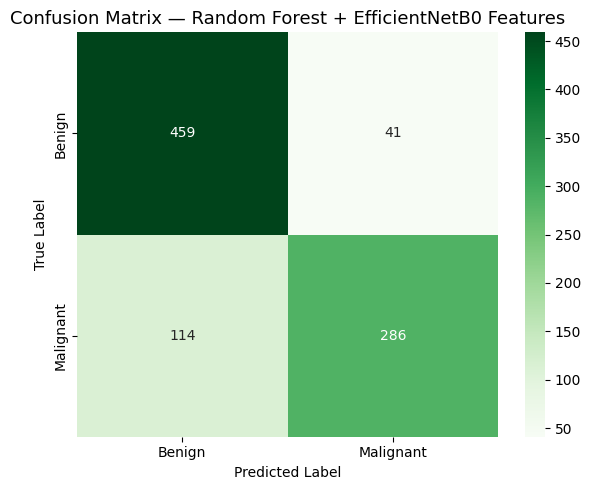

In [59]:
# Confusion matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix — Random Forest + EfficientNetB0 Features", fontsize=13)
plt.tight_layout()
plt.show()

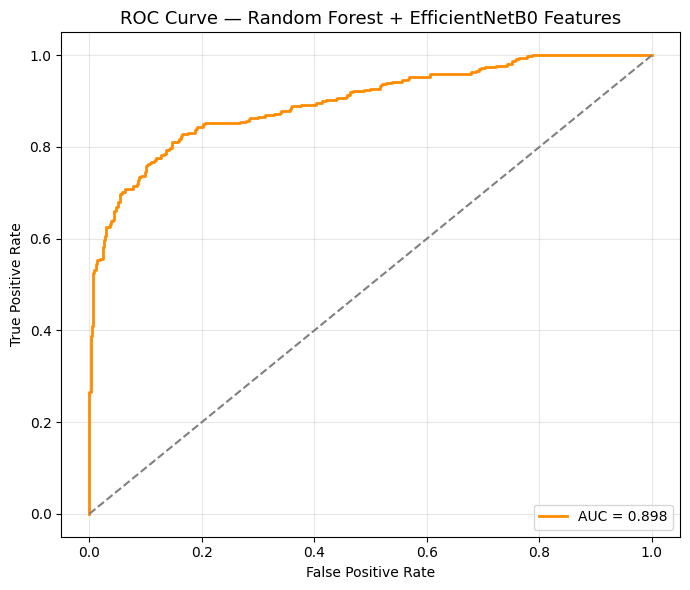

In [60]:
# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(y_val, y_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Random Forest + EfficientNetB0 Features", fontsize=13)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
# Load the trained Random Forest model
rf_model = joblib.load("/kaggle/working/randomforest_ultrasound.model")

# Image size
IMG_SIZE = (224, 224)

# Define EfficientNetB0 feature extractor
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
feature_extractor = tf.keras.models.Model(inputs=base_model.input, outputs=x)

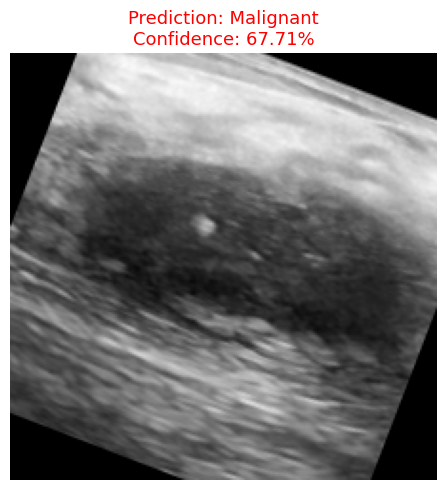

Predicted class: Malignant
Confidence score: 0.6771


In [62]:
# Example: malignant image
img_path = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val/malignant/"
    "malignant (1)-rotated2.png"
)

# Load and preprocess image
img = image.load_img(img_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

# Extract features with EfficientNetB0
features = feature_extractor.predict(img_array, verbose=0)

# Predict with Random Forest
y_prob = rf_model.predict_proba(features)[0][1]
y_pred = int(y_prob > 0.5)

# Interpretation of result
class_names = ["Benign", "Malignant"]
pred_label = class_names[y_pred]
confidence = y_prob if y_pred == 1 else 1 - y_prob

# Visualization
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
color = "red" if pred_label == "Malignant" else "green"
plt.title(f"Prediction: {pred_label}\nConfidence: {confidence:.2%}", color=color, fontsize=13)
plt.tight_layout()
plt.show()

# Console output
print(f"Predicted class: {pred_label}")
print(f"Confidence score: {confidence:.4f}")

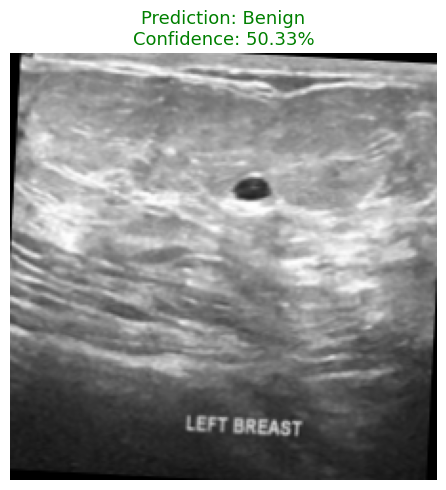

Predicted class: Benign
Confidence score: 0.5033


In [63]:
# Example: benign image
img_path2 = (
    "/kaggle/input/ultrasound-breast-images-for-breast-cancer/"
    "ultrasound breast classification/val/benign/"
    "benign (1)-rotated1.png"
)

# Load and preprocess the image
img = image.load_img(img_path2, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

# Extract features using EfficientNetB0
features = feature_extractor.predict(img_array, verbose=0)

# Predict with the trained Random Forest model
y_prob = rf_model.predict_proba(features)[0][1]
y_pred = int(y_prob > 0.5)

# Interpret the result
class_names = ["Benign", "Malignant"]
pred_label = class_names[y_pred]
confidence = y_prob if y_pred == 1 else 1 - y_prob

# Visualization
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
color = "red" if pred_label == "Malignant" else "green"
plt.title(f"Prediction: {pred_label}\nConfidence: {confidence:.2%}", color=color, fontsize=13)
plt.tight_layout()
plt.show()

# Console output
print(f"Predicted class: {pred_label}")
print(f"Confidence score: {confidence:.4f}")